# CheXWorld on CheXpert dataset

In [1]:
import importlib
import json
import os
import socket
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.metrics import confusion_matrix, precision_recall_curve, roc_curve

WORK = Path('/kaggle/working')
INPUT = Path('/kaggle/input')
WORK.mkdir(parents=True, exist_ok=True)
RUNTIME = WORK / 'chexworld_runtime.py'


In [2]:
# Set the released CheXpert profile
DATA_ROOT = ''
PRETRAINED_WEIGHTS = ''
RUN_NAME = 'chexworld_chexpert'
SEEDS = [0, 1, 2, 3, 4]
SPLIT_SEED = 42

EPOCHS = 1
LEARNING_RATE = 1e-2
WEIGHT_DECAY = 0.4
LAYER_DECAY = 0.55
DROP_PATH = 0.1
WARMUP_EPOCHS = 1
MIN_LR = 1e-6
MICRO_BATCH = 32
ACCUMULATION = 4
EVAL_BATCH = 64
NUM_WORKERS = 2
CLIP_GRAD = 1.0

REPO_COMMIT = '090102758801dc097f53c49d135b835570c8d173'
CHECKPOINT_SHA256 = '175d2c75971daea772d1f338a8cc81540db60fa48f55cbbd9006b2b9b3576a9a'
REPO = WORK / 'CheXWorld-source'
CODE_DIR = WORK / 'chexworld_official'
RESULTS = WORK / RUN_NAME
RESULTS.mkdir(parents=True, exist_ok=True)


In [3]:
# Install the small compatibility dependencies
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--no-deps',
                'timm==0.9.16', 'einops==0.8.1'], check=True)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 35.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 3.0 MB/s eta 0:00:00


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', '--no-deps', 'timm==0.9.16', 'einops==0.8.1'], returncode=0)

In [4]:
GPU_COUNT = torch.cuda.device_count()
if GPU_COUNT != 2:
    raise RuntimeError('Select GPU T4 x2 in Kaggle Session options before running this notebook.')
print('Using:', ', '.join(torch.cuda.get_device_name(i) for i in range(GPU_COUNT)))
print(f'Effective batch: {MICRO_BATCH * GPU_COUNT * ACCUMULATION} | epochs per seed: {EPOCHS}')


Using: Tesla T4, Tesla T4
Effective batch: 256 | epochs per seed: 1


In [5]:
# Download the pinned official source
if not (REPO / '.git').exists():
    subprocess.run(['git', 'clone', '-q', 'https://github.com/LeapLabTHU/CheXWorld.git', str(REPO)], check=True)
subprocess.run(['git', '-C', str(REPO), 'checkout', '-q', REPO_COMMIT], check=True)
revision = subprocess.check_output(['git', '-C', str(REPO), 'rev-parse', 'HEAD'], text=True).strip()
if revision != REPO_COMMIT:
    raise RuntimeError('The source revision does not match the verified release.')


In [6]:
%%writefile {RUNTIME}
# Save the download and official-source helpers
# Helpers for the CheXWorld CheXpert downstream fine-tuning notebook
import ast
import contextlib
import hashlib
import html
import importlib
import json
import math
import os
import random
import re
import shutil
import sys
import time
from datetime import timedelta
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import requests
import torch
import torch.distributed as dist
from PIL import Image
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             precision_recall_curve, precision_recall_fscore_support, roc_auc_score)
from sklearn.model_selection import GroupShuffleSplit
from torch import nn
from torch.utils.data import DataLoader, Dataset, DistributedSampler, Subset

LABELS = ['Atelectasis', 'Cardiomegaly', 'Consolidation', 'Edema', 'Pleural Effusion']


def sha256(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as stream:
        for chunk in iter(lambda: stream.read(8 * 1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


def download_weights(destination, expected_hash):
    destination = Path(destination)
    if destination.exists() and sha256(destination) == expected_hash:
        return destination
    url = 'https://drive.usercontent.google.com/download'
    params = {'id': '1QKUhIWIicl65UXJIGSh7_rYaq5i08iVn', 'export': 'download'}
    with requests.Session() as session:
        response = session.get(url, params=params, stream=True, timeout=(30, 120))
        response.raise_for_status()
        if 'text/html' in response.headers.get('Content-Type', ''):
            page = response.text
            params = {html.unescape(k): html.unescape(v) for k, v in
                      re.findall(r'name="([^"]+)" value="([^"]+)"', page)}
            response.close()
            if params.get('confirm') != 't':
                raise RuntimeError('Drive did not offer the weights. Attach chexworld_pretrained.tar as input.')
            response = session.get(url, params=params, stream=True, timeout=(30, 120))
            response.raise_for_status()
        if 'text/html' in response.headers.get('Content-Type', ''):
            response.close()
            raise RuntimeError('Drive download is unavailable. Attach the official weights as notebook input.')
        destination.parent.mkdir(parents=True, exist_ok=True)
        temporary = destination.with_suffix('.partial')
        with temporary.open('wb') as stream:
            for chunk in response.iter_content(4 * 1024 * 1024):
                stream.write(chunk)
        response.close()
    if sha256(temporary) != expected_hash:
        raise ValueError('Downloaded weights do not match the verified official checkpoint.')
    temporary.replace(destination)
    return destination


def prepare_official_code(repo, destination):
    destination = Path(destination)
    destination.mkdir(parents=True, exist_ok=True)
    (destination / '__init__.py').write_text('')
    files = ['jepa_vit.py', 'jepa_vit_3d.py', 'utils.py', 'pos_embed.py',
             'finetune.py', 'attentive_pooler.py']
    for filename in files:
        shutil.copyfile(Path(repo) / 'models' / filename, destination / filename)
    shutil.copyfile(Path(repo) / 'util/lr_decay.py', destination / 'lr_decay.py')
    shutil.copyfile(Path(repo) / 'util/lr_sched.py', destination / 'lr_sched.py')
    # Extract only the executed classification transform functions, unchanged
    source = (Path(repo) / 'data_utils/xray_transform.py').read_text()
    names = {'Identity', 'get_mean_std', 'build_transform_crop', 'build_transform_xray'}
    pieces = [ast.get_source_segment(source, node) for node in ast.parse(source).body
              if isinstance(node, (ast.ClassDef, ast.FunctionDef)) and node.name in names]
    imports = ('from torchvision import transforms\nfrom PIL import Image\nimport logging\nimport torch\n'
               'from timm.data import create_transform\n'
               'from timm.data.constants import IMAGENET_DEFAULT_MEAN, IMAGENET_DEFAULT_STD, '
               'IMAGENET_INCEPTION_MEAN, IMAGENET_INCEPTION_STD\n')
    # Only the official jit branch is used; avoid importing unused segmentation packages
    aug_source = ast.get_source_segment(source, next(node for node in ast.parse(source).body
        if isinstance(node, ast.FunctionDef) and node.name == 'build_aug_trans'))
    (destination / 'xray_transform.py').write_text(imports + '\n\n'.join(pieces + [aug_source]) + '\n')
    return {filename: sha256(destination / filename) for filename in files +
            ['lr_decay.py', 'lr_sched.py', 'xray_transform.py']}


Writing /kaggle/working/chexworld_runtime.py


In [7]:
%%writefile -a {RUNTIME}
# Save the metadata and patient-split helpers
def read_metadata(csv_path, data_root):
    frame = pd.read_csv(csv_path)
    if not {'Path', 'Frontal/Lateral', *LABELS}.issubset(frame.columns):
        raise ValueError('The CheXpert CSV is missing required columns.')
    frame = frame.loc[frame['Frontal/Lateral'].eq('Frontal')].copy()
    frame['patient_id'] = frame['Path'].str.extract(r'(patient\d+)', expand=False)
    if frame['patient_id'].isna().any() or frame['Path'].duplicated().any():
        raise ValueError('CheXpert paths contain missing patient IDs or duplicate images.')
    for label in LABELS:
        uncertain = 1 if label in ['Atelectasis', 'Edema'] else 0
        frame[label] = frame[label].replace(-1, uncertain).fillna(0).astype(np.float32)
    if not np.isin(frame[LABELS].to_numpy(), [0, 1]).all():
        raise ValueError('The mapped targets must be binary.')
    root = Path(data_root)

    def resolve(raw):
        parts = Path(raw).parts
        split = 'train' if 'train' in parts else 'valid'
        suffix = Path(*parts[parts.index(split):])
        for candidate in [root / raw, root / suffix, root.parent / raw]:
            if candidate.is_file():
                return str(candidate)
        raise FileNotFoundError(f'Missing image: {raw}. Attach the full image dataset.')

    frame['image_path'] = frame['Path'].map(resolve)
    return frame.reset_index(drop=True)


def make_splits(train_csv, valid_csv, data_root, split_seed=42):
    all_train = read_metadata(train_csv, data_root)
    public = read_metadata(valid_csv, data_root)
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=split_seed)
    train_rows, val_rows = next(splitter.split(all_train, groups=all_train.patient_id))
    frames = {'train': all_train.iloc[train_rows].sample(frac=1, random_state=42).reset_index(drop=True),
              'val': all_train.iloc[val_rows].reset_index(drop=True), 'test': public}
    for first, second in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
        if set(frames[first].patient_id) & set(frames[second].patient_id):
            raise ValueError(f'Patients overlap between {first} and {second}.')
    for split, frame in frames.items():
        if (frame[LABELS].nunique() != 2).any():
            raise ValueError(f'{split} must contain both outcomes for each finding.')
    return frames


Appending to /kaggle/working/chexworld_runtime.py


In [8]:
%%writefile -a {RUNTIME}
# Save the official image transforms and dataset adapter
def image_transform(training):
    from chexworld_official.xray_transform import build_transform_xray
    options = SimpleNamespace(norm_type='default', input_size=224, resize_size=256,
        aug_type='jit', crop_type='rrc', scale_min=0.4, color_jitter=0.2, rot=0)
    return build_transform_xray(options, is_train=training, ten_crop=False)


class CheXpertImages(Dataset):
    def __init__(self, manifest, training=False):
        self.frame = pd.read_csv(manifest) if isinstance(manifest, (str, Path)) else manifest.copy()
        self.paths = self.frame.image_path.tolist()
        self.labels = torch.tensor(self.frame[LABELS].to_numpy(dtype=np.float32))
        self.transform = image_transform(training)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            image = self.transform(image.convert('RGB'))
        return image, self.labels[index], index


Appending to /kaggle/working/chexworld_runtime.py


In [9]:
%%writefile -a {RUNTIME}
# Save the strict target-encoder loader
def make_model(checkpoint, drop_path=0.1):
    from chexworld_official.jepa_vit import vit_base
    from chexworld_official.finetune import FineTuner
    encoder = vit_base(img_size=224, patch_size=16, drop_path_rate=drop_path,
                       drop_path_uniform=False)
    # The verified authors' checkpoint contains an argparse Namespace as metadata
    release = torch.load(checkpoint, map_location='cpu', weights_only=False)
    state = {name.removeprefix('target_encoder.'): tensor for name, tensor in release['model'].items()
             if name.startswith('target_encoder.')}
    if not state:
        raise ValueError('The checkpoint contains no target_encoder weights.')
    encoder.load_state_dict(state, strict=True)
    return FineTuner(encoder, feature_dim=768, num_classes=5, tune_type='fc', with_cls_token=False)


def seed_worker(worker_id):
    seed = torch.initial_seed() % (2 ** 32)
    random.seed(seed)
    np.random.seed(seed)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


Appending to /kaggle/working/chexworld_runtime.py


In [10]:
%%writefile -a {RUNTIME}
# Save the distributed prediction helper
@torch.inference_mode()
def evaluate(model, dataset, cfg, device, rank=0, world=1):
    model.eval()
    subset = Subset(dataset, list(range(rank, len(dataset), world)))
    generator = torch.Generator().manual_seed(12345)
    loader = DataLoader(subset, batch_size=cfg['eval_batch'], num_workers=cfg['workers'],
                        pin_memory=device.type == 'cuda', worker_init_fn=seed_worker,
                        generator=generator)
    rows, labels, logits = [], [], []
    for images, targets, indices in loader:
        with torch.autocast(device_type=device.type, enabled=device.type == 'cuda', dtype=torch.float16):
            output = model(images.to(device, non_blocking=True))
        rows.append(indices.numpy())
        labels.append(targets.numpy())
        logits.append(output.float().cpu().numpy())
    local = (np.concatenate(rows), np.concatenate(labels), np.concatenate(logits))
    if world > 1:
        gathered = [None] * world
        dist.all_gather_object(gathered, local)
    else:
        gathered = [local]
    indices = np.concatenate([item[0] for item in gathered])
    order = indices.argsort()
    if not np.array_equal(indices[order], np.arange(len(dataset))):
        raise RuntimeError('Evaluation did not cover each image exactly once.')
    truth = np.concatenate([item[1] for item in gathered])[order]
    scores = np.concatenate([item[2] for item in gathered])[order]
    loss = nn.functional.binary_cross_entropy_with_logits(torch.from_numpy(scores), torch.from_numpy(truth)).item()
    probabilities = torch.from_numpy(scores).double().sigmoid().numpy()
    aucs = [roc_auc_score(truth[:, i], scores[:, i]) for i in range(5)]
    return {'loss': loss, 'macro_auroc': float(np.mean(aucs))}, truth, probabilities


Appending to /kaggle/working/chexworld_runtime.py


In [11]:
%%writefile -a {RUNTIME}
# Save the threshold and metric helpers
def choose_thresholds(truth, probabilities):
    thresholds = []
    for index in range(5):
        precision, recall, values = precision_recall_curve(truth[:, index], probabilities[:, index])
        f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
        thresholds.append(float(values[int(np.argmax(f1))]))
    return thresholds


def metrics_table(truth, probabilities, thresholds):
    records = []
    for index, label in enumerate(LABELS):
        y, p = truth[:, index], probabilities[:, index]
        predicted = p >= thresholds[index]
        precision, recall, f1, _ = precision_recall_fscore_support(y, predicted, average='binary', zero_division=0)
        records.append(dict(label=label, AUROC=roc_auc_score(y, p), AUPRC=average_precision_score(y, p),
            accuracy=accuracy_score(y, predicted), precision=precision, recall=recall, F1=f1,
            threshold=thresholds[index]))
    return pd.DataFrame(records).set_index('label')


def save_scores(directory, name, dataset, truth, probabilities):
    frame = dataset.frame[['Path', 'patient_id', *LABELS]].copy()
    for index, label in enumerate(LABELS):
        frame[label + '_probability'] = probabilities[:, index]
    frame.to_csv(Path(directory) / f'{name}_predictions.csv', index=False)


Appending to /kaggle/working/chexworld_runtime.py


In [12]:
%%writefile -a {RUNTIME}
# Save the full fine-tuning step
def train_epoch(model, loader, optimizer, scaler, cfg, epoch, device, rank, directory):
    from chexworld_official.lr_sched import adjust_learning_rate
    options = SimpleNamespace(lr=cfg['learning_rate'], min_lr=cfg['min_lr'],
                              warmup_epochs=cfg['warmup_epochs'], epochs=cfg['epochs'])
    model.train()
    optimizer.zero_grad(set_to_none=True)
    accumulation = cfg['accumulation']
    usable_batches = len(loader) // accumulation * accumulation
    if not usable_batches:
        raise ValueError('Training data is too small for the configured effective batch.')
    records, totals = [], torch.zeros(2, device=device, dtype=torch.float64)
    start = time.perf_counter()
    for step, (images, targets, _) in enumerate(loader):
        if step >= usable_batches:
            break
        lr = adjust_learning_rate(optimizer, epoch + step / len(loader), options)
        update = (step + 1) % accumulation == 0
        sync = contextlib.nullcontext() if update or not hasattr(model, 'no_sync') else model.no_sync()
        with sync:
            with torch.autocast(device_type=device.type, enabled=device.type == 'cuda', dtype=torch.float16):
                output = model(images.to(device, non_blocking=True))
                loss = nn.functional.binary_cross_entropy_with_logits(output, targets.to(device, non_blocking=True))
            if not torch.isfinite(loss):
                raise FloatingPointError('Non-finite training loss; no result will be reported.')
            scaler.scale(loss / accumulation).backward()
        totals[0] += loss.detach().double() * len(images)
        totals[1] += len(images)
        if update:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg['clip_grad'])
            previous_scale = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            skipped = scaler.get_scale() < previous_scale
            optimizer.zero_grad(set_to_none=True)
            if rank == 0:
                row = dict(epoch=epoch + 1, micro_step=step + 1,
                    update=(step + 1) // accumulation, loss=float(loss.detach()), lr=lr,
                    amp_skipped=int(skipped), elapsed_seconds=time.perf_counter() - start)
                records.append(row)
                if row['update'] == 1 or row['update'] % cfg['log_every'] == 0:
                    print(f"Epoch {epoch + 1}/{cfg['epochs']} | update {row['update']}/{usable_batches // accumulation}"
                          f" | loss {row['loss']:.4f} | LR {lr:.5f}", flush=True)
    if dist.is_initialized():
        dist.all_reduce(totals)
    if rank == 0:
        destination = Path(directory) / 'steps.csv'
        pd.DataFrame(records).to_csv(destination, mode='a', header=not destination.exists(), index=False)
    return float(totals[0] / totals[1]), time.perf_counter() - start


Appending to /kaggle/working/chexworld_runtime.py


In [13]:
%%writefile -a {RUNTIME}
# Save the training and final-evaluation procedure
def run_seed(cfg, seed, rank, world, device):
    from chexworld_official.lr_decay import param_groups_lrd
    directory = Path(cfg['results']) / f'seed{seed}'
    directory.mkdir(parents=True, exist_ok=True)
    set_seed(seed + rank)
    train_data = CheXpertImages(cfg['train_manifest'], training=True)
    val_data = CheXpertImages(cfg['val_manifest'])
    test_data = CheXpertImages(cfg['test_manifest'])
    sampler = DistributedSampler(train_data, num_replicas=world, rank=rank, shuffle=True)
    generator = torch.Generator().manual_seed(seed + rank)
    loader = DataLoader(train_data, sampler=sampler, batch_size=cfg['micro_batch'],
        num_workers=cfg['workers'], pin_memory=device.type == 'cuda', drop_last=True,
        persistent_workers=cfg['workers'] > 0, worker_init_fn=seed_worker, generator=generator)
    model = make_model(cfg['checkpoint'], cfg['drop_path']).to(device)
    if world > 1:
        model = nn.parallel.DistributedDataParallel(model,
            device_ids=[device.index] if device.type == 'cuda' else None, broadcast_buffers=False)
    raw_model = model.module if hasattr(model, 'module') else model
    groups = param_groups_lrd(raw_model, weight_decay=cfg['weight_decay'],
        no_weight_decay_list=['pos_embed', 'cls_token', 'head.cls_query', 'prompt'], layer_decay=cfg['layer_decay'])
    optimizer = torch.optim.AdamW(groups, lr=cfg['learning_rate'], betas=(0.9, 0.999))
    scaler = torch.amp.GradScaler('cuda', enabled=device.type == 'cuda')
    history, best_auc, best_loss = [], -math.inf, math.inf
    best_epoch, stale = 0, 0
    training_seconds, val_seconds = 0.0, 0.0
    run_start = time.perf_counter()
    for epoch in range(cfg['epochs']):
        sampler.set_epoch(epoch)
        if rank == 0:
            print(f'Seed {seed} | full encoder fine-tuning | epoch {epoch + 1}/{cfg["epochs"]}', flush=True)
        train_loss, seconds = train_epoch(model, loader, optimizer, scaler, cfg, epoch, device, rank, directory)
        training_seconds += seconds
        start = time.perf_counter()
        val_stats, val_truth, val_probs = evaluate(raw_model, val_data, cfg, device, rank, world)
        val_seconds += time.perf_counter() - start
        improved = val_stats['macro_auroc'] > best_auc or val_stats['loss'] < best_loss
        best_auc = max(best_auc, val_stats['macro_auroc'])
        best_loss = min(best_loss, val_stats['loss'])
        stale = 0 if improved else stale + 1
        history.append(dict(epoch=epoch + 1, train_loss=train_loss, val_loss=val_stats['loss'],
                            val_auroc=val_stats['macro_auroc'], training_seconds=seconds))
        if rank == 0:
            if improved:
                best_epoch = epoch + 1
                torch.save(dict(model=raw_model.state_dict(), epoch=best_epoch, seed=seed,
                                config=cfg), directory / 'best.pt')
                save_scores(directory, 'validation', val_data, val_truth, val_probs)
            pd.DataFrame(history).to_csv(directory / 'history.csv', index=False)
            print(f"Epoch {epoch + 1:02d}/{cfg['epochs']} | train loss {train_loss:.4f}"
                  f" | val loss {val_stats['loss']:.4f} | val AUROC {val_stats['macro_auroc']:.4f}", flush=True)
        if world > 1:
            dist.barrier()
        if stale >= cfg['patience']:
            break
    # Reload the selected development checkpoint before accessing the public benchmark.
    selected = torch.load(directory / 'best.pt', map_location=device, weights_only=False)
    raw_model.load_state_dict(selected['model'], strict=True)
    del selected
    if rank == 0:
        print(f'Seed {seed} | evaluating selected checkpoint on public validation images', flush=True)
    start = time.perf_counter()
    test_stats, truth, probabilities = evaluate(raw_model, test_data, cfg, device, rank, world)
    test_seconds = time.perf_counter() - start
    if rank == 0:
        saved = pd.read_csv(directory / 'validation_predictions.csv')
        val_probabilities = saved[[label + '_probability' for label in LABELS]].to_numpy()
        thresholds = choose_thresholds(saved[LABELS].to_numpy(), val_probabilities)
        table = metrics_table(truth, probabilities, thresholds)
        table.to_csv(directory / 'metrics.csv')
        metrics_table(truth, probabilities, [0.5] * 5).to_csv(directory / 'metrics_threshold_0_5.csv')
        save_scores(directory, 'public_validation', test_data, truth, probabilities)
        summary = dict(seed=seed, best_epoch=best_epoch, macro_auroc=test_stats['macro_auroc'],
            training_seconds=training_seconds, development_validation_seconds=val_seconds,
            test_seconds=test_seconds, total_seconds=time.perf_counter() - run_start,
            thresholds=thresholds, completed=True)
        (directory / 'summary.json').write_text(json.dumps(summary, indent=2))
        print(f"Seed {seed} | public-validation macro AUROC {test_stats['macro_auroc']:.4f}"
              f" | fine-tuning {training_seconds / 60:.1f} min", flush=True)
    del model, raw_model, optimizer, loader, scaler
    if device.type == 'cuda':
        torch.cuda.empty_cache()


Appending to /kaggle/working/chexworld_runtime.py


In [14]:
%%writefile -a {RUNTIME}
# Save the two-GPU repetition runner
def run_training(config_path):
    cfg = json.loads(Path(config_path).read_text())
    world = int(os.environ.get('WORLD_SIZE', '1'))
    rank = int(os.environ.get('RANK', '0'))
    local_rank = int(os.environ.get('LOCAL_RANK', '0'))
    use_cuda = torch.cuda.is_available()
    device = torch.device('cuda', local_rank) if use_cuda else torch.device('cpu')
    if use_cuda:
        torch.cuda.set_device(local_rank)
    else:
        torch.set_num_threads(2)
    if world > 1:
        dist.init_process_group('nccl' if use_cuda else 'gloo', timeout=timedelta(minutes=60))
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = False
    if cfg['micro_batch'] * cfg['accumulation'] * world != cfg['effective_batch']:
        raise ValueError('GPU count, micro-batch, and accumulation do not match the configured effective batch.')
    try:
        for seed in cfg['seeds']:
            summary = Path(cfg['results']) / f'seed{seed}' / 'summary.json'
            if summary.exists():
                if rank == 0:
                    print(f'Seed {seed} already completed; keeping its saved result.', flush=True)
                continue
            # An interrupted seed restarts from the verified pretrained weights.
            directory = summary.parent
            if rank == 0 and directory.exists():
                shutil.rmtree(directory)
            if world > 1:
                dist.barrier()
            run_seed(cfg, seed, rank, world, device)
            if world > 1:
                dist.barrier()
    finally:
        if dist.is_initialized():
            dist.destroy_process_group()


if __name__ == '__main__':
    run_training(sys.argv[1])


Appending to /kaggle/working/chexworld_runtime.py


In [15]:
# Load the helpers and isolate the official classification modules
if str(WORK) not in sys.path:
    sys.path.insert(0, str(WORK))
import chexworld_runtime as cw
importlib.reload(cw)
SOURCE_HASHES = cw.prepare_official_code(REPO, CODE_DIR)
LABELS = cw.LABELS
print('Official encoder, classifier, transforms, and optimizer helpers ready.')


Official encoder, classifier, transforms, and optimizer helpers ready.


In [16]:
# Find the CheXpert CSV files in the attached dataset
if DATA_ROOT:
    data_root = Path(DATA_ROOT)
else:
    choices = []
    for folder, directories, files in os.walk(INPUT):
        directories[:] = [d for d in directories if d not in {'train', 'valid', 'test'}
                          and not d.startswith('patient')]
        if {'train.csv', 'valid.csv'}.issubset(files):
            choices.append(Path(folder))
    if len(choices) != 1:
        raise FileNotFoundError('Attach one CheXpert image dataset with train.csv and valid.csv, or set DATA_ROOT.')
    data_root = choices[0]
print('CheXpert:', data_root)


CheXpert: /kaggle/input/datasets/ashery/chexpert


In [17]:
# Prepare and save the fixed patient-separated development split
frames = cw.make_splits(data_root / 'train.csv', data_root / 'valid.csv', data_root, SPLIT_SEED)
manifest_hashes = {}
for split, frame in frames.items():
    path = RESULTS / f'{split}_manifest.csv'
    if path.exists() and path.read_text() != frame.to_csv(index=False):
        raise ValueError('Saved split differs from this dataset or SPLIT_SEED; use a new RUN_NAME.')
    frame.to_csv(path, index=False)
    manifest_hashes[split] = cw.sha256(path)
    name = 'Public validation (final evaluation)' if split == 'test' else split.capitalize()
    print(f'{name}: {len(frame):,} images | {frame.patient_id.nunique():,} patients')
print('Development split reconstructed from train.csv; the authors did not release its exact membership.')


Train: 171,927 images | 58,080 patients
Val: 19,100 images | 6,454 patients
Public validation (final evaluation): 202 images | 200 patients
Development split reconstructed from train.csv; the authors did not release its exact membership.


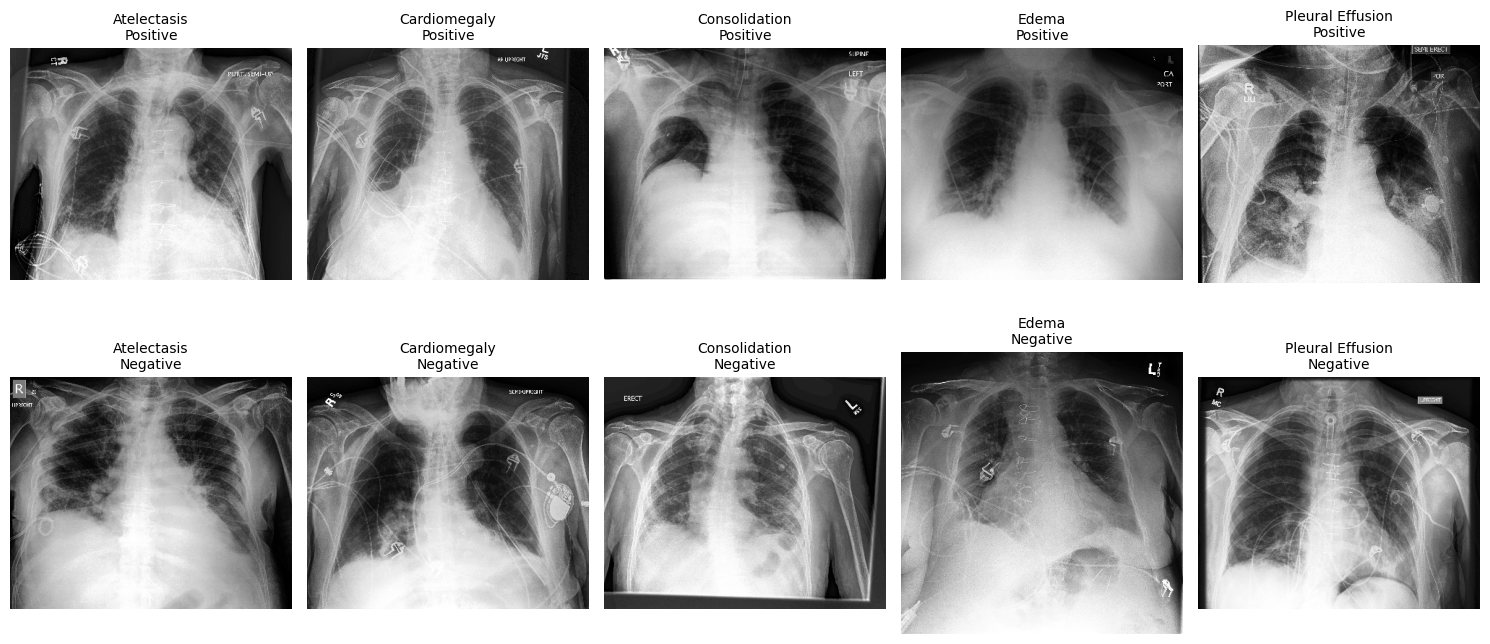

In [18]:
# Show positive and negative training examples for each finding
fig, axes = plt.subplots(2, 5, figsize=(15, 7))
for column, label in enumerate(LABELS):
    for row, target in enumerate([1, 0]):
        sample = frames['train'].loc[frames['train'][label].eq(target)].sample(1, random_state=SPLIT_SEED).iloc[0]
        with Image.open(sample.image_path) as image:
            axes[row, column].imshow(image.convert('L'), cmap='gray')
        axes[row, column].set_title(label + '\n' + ('Positive' if target else 'Negative'), fontsize=10)
        axes[row, column].axis('off')
fig.tight_layout()
fig.savefig(RESULTS / 'sample_images.png', dpi=160)
plt.show()
plt.close(fig)


In [19]:
# Find or download the verified authors' pretrained weights
if PRETRAINED_WEIGHTS:
    checkpoint = Path(PRETRAINED_WEIGHTS)
else:
    attached = list(INPUT.rglob('chexworld_pretrained.tar'))
    if len(attached) > 1:
        raise ValueError('Select one checkpoint with PRETRAINED_WEIGHTS.')
    checkpoint = attached[0] if attached else cw.download_weights(WORK / 'chexworld_pretrained.tar', CHECKPOINT_SHA256)
if cw.sha256(checkpoint) != CHECKPOINT_SHA256:
    raise ValueError('The checkpoint differs from the verified official release.')
print('Verified pretrained checkpoint:', checkpoint)


Verified pretrained checkpoint: /kaggle/working/chexworld_pretrained.tar


In [20]:
# Check the complete encoder load and classifier output before training
model = cw.make_model(checkpoint, DROP_PATH).eval()
sample, _, _ = cw.CheXpertImages(frames['test'])[0]
with torch.inference_mode():
    output = model(sample.unsqueeze(0))
if output.shape != (1, 5) or not torch.isfinite(output).all():
    raise RuntimeError('The model did not produce five finite classification logits.')
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
if not all(p.requires_grad for name, p in model.feature_model.named_parameters() if name != 'pos_embed'):
    raise RuntimeError('The encoder must be fully trainable, apart from the official fixed positional embedding.')
print(f'Strict encoder load passed | trainable parameters: {trainable:,}')
del model, sample, output


/usr/lib/python3.13/contextlib.py:109: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)


Strict encoder load passed | trainable parameters: 85,650,437


In [21]:
# Save the training configuration and environment details
cfg = dict(
    results=str(RESULTS),
    checkpoint=str(checkpoint),
    seeds=SEEDS,
    split_seed=SPLIT_SEED,
    dataset='CheXpert frontal-only five-label classification',
    input_size=224,
    resize_size=256,
    optimizer='AdamW',
    betas=[0.9, 0.999],
    loss='unweighted BCEWithLogitsLoss',
    amp='FP16',
    normalization='ImageNet default',
    training_augmentation='random resized crop (0.4,1), flip, brightness/contrast jitter 0.2',
    uncertain_mapping={label: int(label in ['Atelectasis', 'Edema']) for label in LABELS},
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    layer_decay=LAYER_DECAY,
    drop_path=DROP_PATH,
    warmup_epochs=WARMUP_EPOCHS,
    min_lr=MIN_LR,
    micro_batch=MICRO_BATCH,
    accumulation=ACCUMULATION,
    effective_batch=MICRO_BATCH * GPU_COUNT * ACCUMULATION,
    eval_batch=EVAL_BATCH,
    workers=NUM_WORKERS,
    clip_grad=CLIP_GRAD,
    patience=15,
    log_every=50,
    repo_commit=REPO_COMMIT,
    checkpoint_sha256=CHECKPOINT_SHA256,
    manifest_hashes=manifest_hashes,
    source_hashes=SOURCE_HASHES,
    protocol='patient-separated reconstructed development split',
    **{split + '_manifest': str(RESULTS / f'{split}_manifest.csv') for split in frames}
)

config_path = RESULTS / 'config.json'
if config_path.exists():
    previous_config = json.loads(config_path.read_text())
    previous_config.pop('time_budget_hours', None)
    if previous_config != cfg:
        raise ValueError('Configuration changed; choose a new RUN_NAME.')

config_path.write_text(json.dumps(cfg, indent=2))
(RESULTS / 'environment.txt').write_text(
    subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True)
)
(RESULTS / 'hardware.json').write_text(json.dumps(dict(
    torch=torch.__version__,
    cuda=torch.version.cuda,
    gpus=[torch.cuda.get_device_name(i) for i in range(GPU_COUNT)]
), indent=2))
print('Training configuration and environment details saved.')

Training configuration and environment details saved.


In [22]:
# Fine-tune and evaluate using both GPUs while saving the training log
with socket.socket() as connection:
    connection.bind(('127.0.0.1', 0))
    port = connection.getsockname()[1]
command = [sys.executable, '-u', '-m', 'torch.distributed.run', '--nnodes=1',
    '--nproc_per_node=2', '--master_addr=127.0.0.1', f'--master_port={port}',
    str(RUNTIME), str(config_path)]
environment = os.environ.copy()
environment['OMP_NUM_THREADS'] = '2'
environment['PYTHONUNBUFFERED'] = '1'
environment['PYTHONPATH'] = str(WORK) + os.pathsep + environment.get('PYTHONPATH', '')
with (RESULTS / 'training.log').open('a') as log:
    process = subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
        text=True, bufsize=1, cwd=WORK, env=environment)
    for line in process.stdout:
        print(line, end='')
        log.write(line)
        log.flush()
    returncode = process.wait()
if returncode:
    raise RuntimeError(f'Training failed with exit code {returncode}; read the final lines of training.log.')


/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)
[rank0]:[W1018 08:17:23.865912466 ProcessGroupNCCL.cpp:5188] Guessing device ID based on global rank. This can cause a hang if rank to GPU mapping is heterogeneous. You can specify device_id in init_process_group()
Seed 0 | full encoder fine-tuning | epoch 1/1
/usr/lib/python3.13/contextlib.py:109: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
/usr/lib/python3.13/contextlib.py:109: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` f

In [23]:
summaries, tables = [], []
for seed in SEEDS:
    directory = RESULTS / f'seed{seed}'
    if not (directory / 'summary.json').exists():
        continue
    summaries.append(json.loads((directory / 'summary.json').read_text()))
    table = pd.read_csv(directory / 'metrics.csv')
    table['seed'] = seed
    tables.append(table)
if not summaries:
    raise RuntimeError('No seed completed; inspect training.log.')
summary = pd.DataFrame(summaries)
summary.to_csv(RESULTS / 'run_summary.csv', index=False)
all_metrics = pd.concat(tables, ignore_index=True)
combined = all_metrics.groupby('label', sort=False).agg({column: ['mean', 'std'] for column in
    ['AUROC', 'AUPRC', 'accuracy', 'precision', 'recall', 'F1']})
combined.to_csv(RESULTS / 'metrics_across_seeds.csv')
display(combined.round(4))
mean = summary.macro_auroc.mean()
std = summary.macro_auroc.std(ddof=1)
print(f'Completed {len(summary)}/{len(SEEDS)} seeds | macro AUROC {mean:.4f}' +
      (f' ± {std:.4f}' if len(summary) > 1 else ' (single run)'))
print('Published reference: 0.8963 ± 0.0013 across five runs; protocol differences are recorded in provenance.json.')
print(f'Total full fine-tuning time: {summary.training_seconds.sum() / 60:.1f} minutes')
FIGURE_SEED = int(summary.seed.iloc[0])  # First completed seed, without selecting by test performance.
figure_dir = RESULTS / f'seed{FIGURE_SEED}'


AUROC           AUPRC         accuracy         precision  \
                    mean     std    mean     std     mean     std      mean   
label                                                                         
Atelectasis       0.8144  0.0112  0.6588  0.0105   0.7515  0.0123    0.6227   
Cardiomegaly      0.8048  0.0095  0.7091  0.0144   0.7436  0.0054    0.8459   
Consolidation     0.8864  0.0304  0.5797  0.0694   0.8594  0.0236    0.5792   
Edema             0.9344  0.0026  0.8064  0.0133   0.8465  0.0086    0.5840   
Pleural Effusion  0.9141  0.0069  0.8395  0.0095   0.8267  0.0099    0.7216   

                          recall              F1          
                     std    mean     std    mean     std  
label                                                     
Atelectasis       0.0135  0.8400  0.0163  0.7151  0.0130  
Cardiomegaly      0.0326  0.2636  0.0173  0.4016  0.0196  
Consolidation     0.1087  0.4125  0.1135  0.4776  0.1057  
Edema             0.0165  0.9143  0.0213  0.7125  0.0120  
Pleural Effusion  0.0087  0.7375  0.0373  0.7292  0.0206

Completed 5/5 seeds | macro AUROC 0.8708 ± 0.0055
Published reference: 0.8963 ± 0.0013 across five runs; protocol differences are recorded in provenance.json.
Total full fine-tuning time: 70.7 minutes


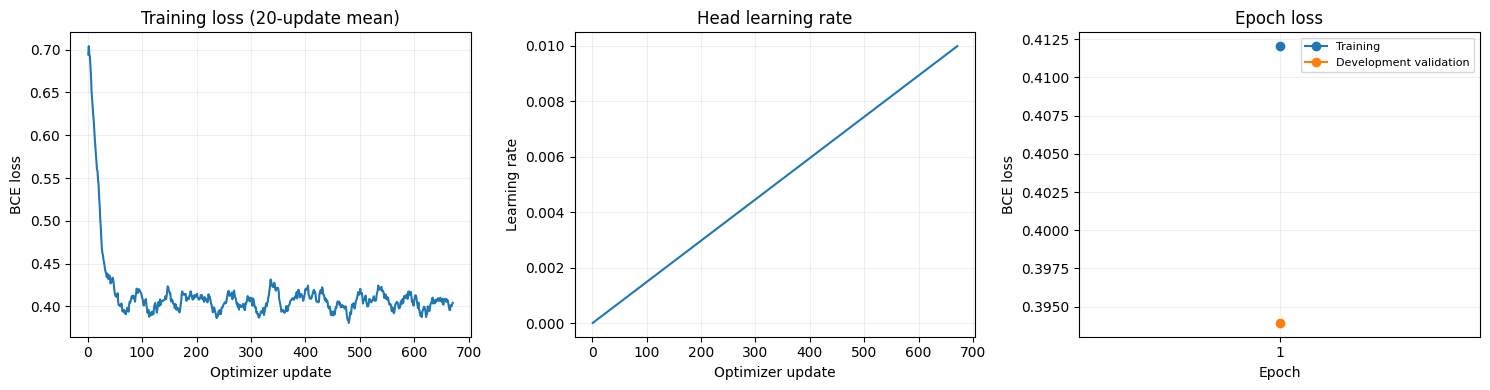

In [24]:
# Plot actual training updates, learning rates, and epoch-level validation loss
steps = pd.read_csv(figure_dir / 'steps.csv')
history = pd.read_csv(figure_dir / 'history.csv')
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(np.arange(1, len(steps) + 1), steps.loss.rolling(20, min_periods=1).mean())
axes[0].set(title='Training loss (20-update mean)', xlabel='Optimizer update', ylabel='BCE loss')
axes[1].plot(np.arange(1, len(steps) + 1), steps.lr)
axes[1].set(title='Head learning rate', xlabel='Optimizer update', ylabel='Learning rate')
axes[2].plot(history.epoch, history.train_loss, 'o-', label='Training')
axes[2].plot(history.epoch, history.val_loss, 'o-', label='Development validation')
axes[2].set(title='Epoch loss', xlabel='Epoch', ylabel='BCE loss', xticks=history.epoch)
axes[2].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(figure_dir / 'learning_curves.png', dpi=180)
plt.show()
plt.close(fig)


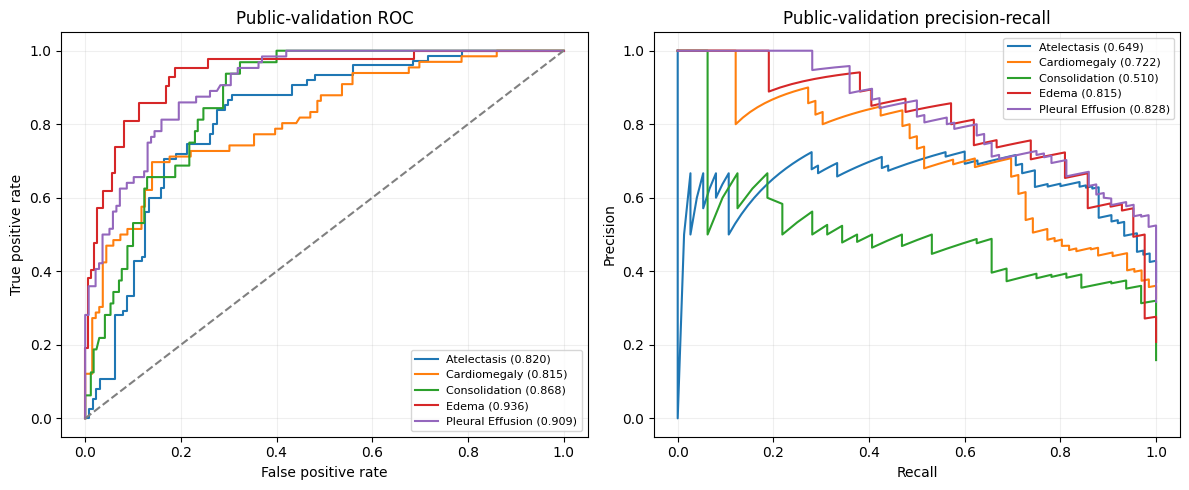

In [25]:
# Plot final ROC and precision-recall curves for the first completed seed
predictions = pd.read_csv(figure_dir / 'public_validation_predictions.csv')
metrics = pd.read_csv(figure_dir / 'metrics.csv').set_index('label')
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for label in LABELS:
    truth, probability = predictions[label], predictions[label + '_probability']
    fpr, tpr, _ = roc_curve(truth, probability)
    precision, recall, _ = precision_recall_curve(truth, probability)
    axes[0].plot(fpr, tpr, label=f'{label} ({metrics.loc[label, "AUROC"]:.3f})')
    axes[1].plot(recall, precision, label=f'{label} ({metrics.loc[label, "AUPRC"]:.3f})')
axes[0].plot([0, 1], [0, 1], '--', color='gray')
axes[0].set(title='Public-validation ROC', xlabel='False positive rate', ylabel='True positive rate')
axes[1].set(title='Public-validation precision-recall', xlabel='Recall', ylabel='Precision')
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(figure_dir / 'roc_pr_curves.png', dpi=180)
plt.show()
plt.close(fig)


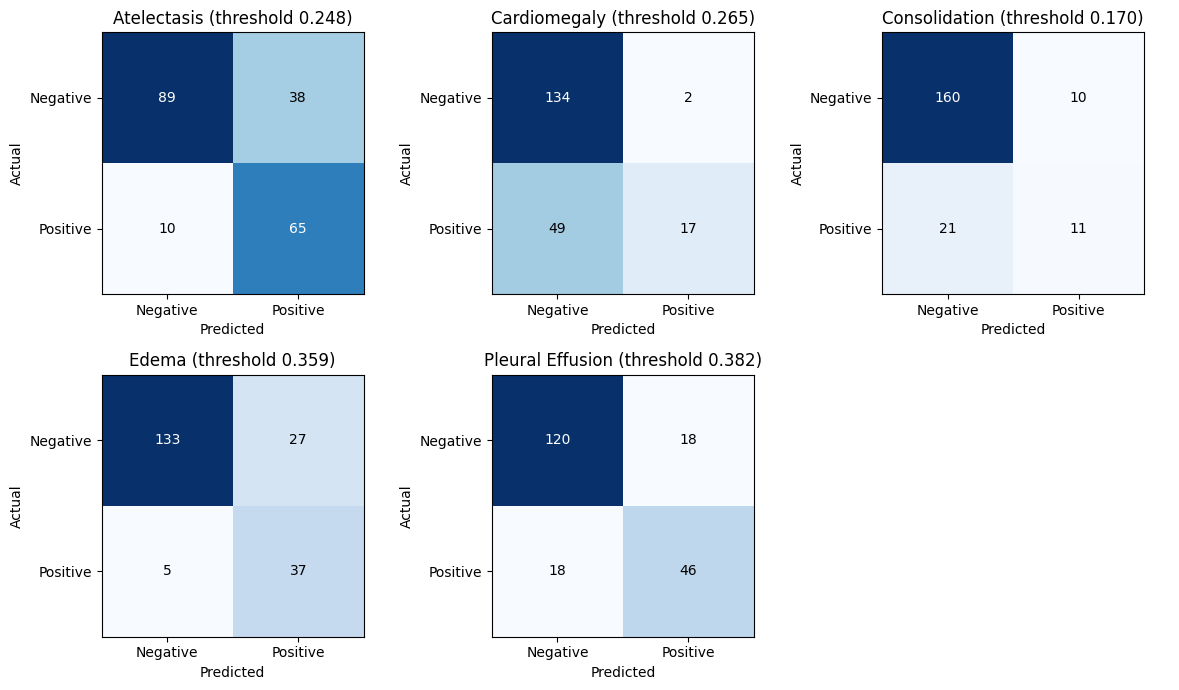

In [26]:
# Plot confusion matrices using thresholds chosen on development data
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for index, label in enumerate(LABELS):
    ax = axes.flat[index]
    threshold = metrics.loc[label, 'threshold']
    matrix = confusion_matrix(predictions[label], predictions[label + '_probability'] >= threshold, labels=[0, 1])
    ax.imshow(matrix, cmap='Blues')
    for row in range(2):
        for column in range(2):
            ax.text(column, row, str(matrix[row, column]), ha='center', va='center',
                    color='white' if matrix[row, column] > matrix.max() / 2 else 'black')
    ax.set(title=f'{label} (threshold {threshold:.3f})', xlabel='Predicted', ylabel='Actual',
           xticks=[0, 1], yticks=[0, 1], xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
axes.flat[-1].axis('off')
fig.tight_layout()
fig.savefig(figure_dir / 'confusion_matrices.png', dpi=180)
plt.show()
plt.close(fig)


In [27]:
# List the saved experiment artifacts and timing
display(summary[['seed', 'best_epoch', 'macro_auroc', 'training_seconds', 'test_seconds', 'total_seconds']].round(3))
print('Results:', RESULTS)
print('Saved: model checkpoints, split manifests, settings, logs, predictions, metrics, figures, and timing.')


,seed,best_epoch,macro_auroc,training_seconds,test_seconds,total_seconds
0,0,1,0.870,879.179,1.631,962.621
1,1,1,0.869,839.733,1.370,907.169
2,2,1,0.864,842.058,1.154,903.204
3,3,1,0.876,839.885,1.136,900.612
4,4,1,0.876,840.702,1.160,901.678


Results: /kaggle/working/chexworld_chexpert
Saved: model checkpoints, split manifests, settings, logs, predictions, metrics, figures, and timing.
